In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score

### Data Preparation

In [2]:
df = pd.read_csv(r'C:\Users\Виталий\PycharmProjects\MLZoomcamp2026\course_lead_scoring_2026.csv')
cat_cols = ['lead_source', 'industry', 'employment_status', 'location']
num_cols = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

df[cat_cols] = df[cat_cols].fillna("NA")
df[num_cols] = df[num_cols].fillna(0.0)
df.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

### Split dataset

In [3]:
df_full_train, df_test = train_test_split(df, test_size = 0.2, random_state = 1)
df_train, df_val = train_test_split(df_full_train, test_size = 0.25, random_state = 1)

df_train.reset_index(drop = True)
df_val.reset_index(drop = True)
df_test.reset_index(drop = True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

## Question 1

In [4]:
for col in num_cols:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])

    print(f"{col} AUC: {auc}")

annual_income AUC: 0.6081977776250831
number_of_courses_viewed AUC: 0.7229894623989618
interaction_count AUC: 0.7649203047563227
lead_score AUC: 0.7882254810906102


## Question 2

### One-hot encoding

In [5]:
dv = DictVectorizer(sparse=False)

train_dict = df_train.to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val.to_dict(orient='records')
X_val = dv.transform(val_dict)

### Training model

In [6]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict_proba(X_val)[:, 1]

auc = np.round(roc_auc_score(y_val, y_pred), 3)
print(auc)

0.732


## Question 3

In [7]:
thresholds = np.linspace(0, 1, 101)

scores = []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns = columns)

df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)

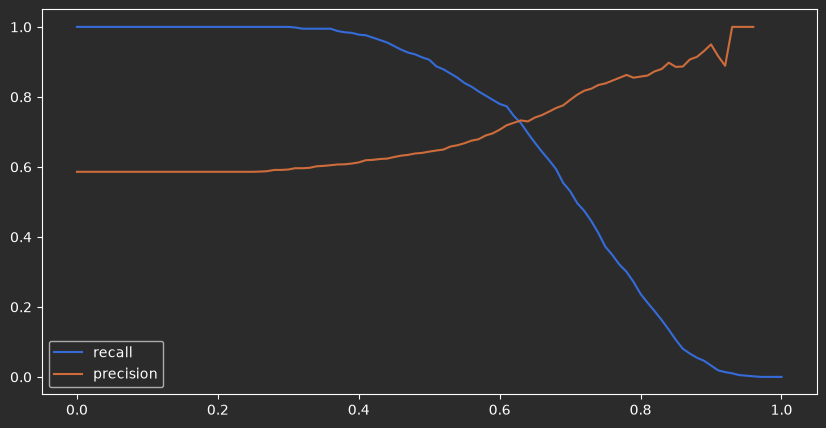

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(df_scores.threshold, df_scores.recall, label = 'recall')
plt.plot(df_scores.threshold, df_scores.precision, label = 'precision')
plt.legend()
plt.show()

In [13]:
print(df_scores[df_scores.threshold == 0.63])
print(df_scores[df_scores.threshold == 0.73])

    threshold   tp   fp   fn   tn    recall  precision
63       0.63  425  155  161  259  0.725256   0.732759
    threshold   tp  fp   fn   tn    recall  precision
73       0.73  261  56  325  358  0.445392   0.823344


## Question 4

In [17]:
df_scores['f1'] = 2 * df_scores.recall * df_scores.precision / (df_scores.recall + df_scores.precision)

In [18]:
max_f1 = max(df_scores.f1.values)
max_f1

np.float64(0.7576158940397352)

In [19]:
print(df_scores[df_scores['f1'] == max_f1])

    threshold   tp   fp  fn  tn    recall  precision        f1
41       0.41  572  352  14  62  0.976109   0.619048  0.757616


## Question 5

In [20]:
def train(df, y, C=1.0):
    dicts = df[cat_cols + num_cols].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y)
    return dv, model

def predict(df, dv, model):
    dicts = df[cat_cols + num_cols].to_dict(orient='records')
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

In [21]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)

    scores.append(auc)

print('%.3f +- %.3f' % (np.mean(scores), np.std(scores)))


0.732 +- 0.007


## Question 6

In [23]:
for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)

        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=1 0.732 +- 0.007
